In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set plot style
sns.set(style="whitegrid")

# Load the dataset
try:
    df = pd.read_csv('D:/Projects/RockWatch/data/raw/master_log.csv')
except FileNotFoundError:
    print("Error: 'master_log.csv' not found. Make sure it's in the same directory.")
    # In a real scenario, you'd handle this more gracefully

# --- 1. Initial Inspection ---

print("--- Data Head ---")
print(df.head())
print("\n")


--- Data Head ---
   global_hour  scenario_id  hour_in_scenario  rainfall_mm  temperature_C  \
0            1            1                 1          0.0         1.0048   
1            2            1                 2          0.0         0.2556   
2            3            1                 3          0.0         0.0000   
3            4            1                 4          0.0         0.2556   
4            5            1                 5          0.0         1.0048   

   vibration_hz  wind_speed_kmh  ground_saturation_pct  freeze_thaw_cycles  \
0             0         13.5836                    0.0                   0   
1             0          9.3472                    0.0                   0   
2             0          6.0116                    0.0                   0   
3             0          8.9326                    0.0                   0   
4             0         13.5710                    0.0                   0   

   consecutive_rain_hours  ...  weathering_factor 

In [3]:
print("--- Data Info (Types and Nulls) ---")
df.info()
print("\n")

print("--- Summary Statistics (Numeric Features) ---")
# Use .describe() to get a statistical summary of all numeric columns
print(df.describe())
print("\n")

print("--- Unique Values in Categorical Columns ---")
# 'LABEL' and 'trigger_reason' are likely key categorical features
print(f"Unique LABELs: {df['LABEL'].unique()}")
print(f"Unique trigger_reasons: {df['trigger_reason'].unique()}")

--- Data Info (Types and Nulls) ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5970 entries, 0 to 5969
Data columns (total 21 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   global_hour                    5970 non-null   int64  
 1   scenario_id                    5970 non-null   int64  
 2   hour_in_scenario               5970 non-null   int64  
 3   rainfall_mm                    5970 non-null   float64
 4   temperature_C                  5970 non-null   float64
 5   vibration_hz                   5970 non-null   int64  
 6   wind_speed_kmh                 5970 non-null   float64
 7   ground_saturation_pct          5970 non-null   float64
 8   freeze_thaw_cycles             5970 non-null   int64  
 9   consecutive_rain_hours         5970 non-null   int64  
 10  rainfall_intensity_mm_hr       5970 non-null   float64
 11  weathering_factor              5970 non-null   float64
 12  daily_max_te

* Scenario-Based: The data is structured by scenario_id (38 total scenarios) and hour_in_scenario (up to 168 hours, or 7 days). This confirms the data is a collection of independent time-series sequences, which is ideal for time-series modeling.

* Highly Imbalanced: The dataset is severely imbalanced. Thus very challenging for modeling
* STABLE: 6,289 instances (~99.4%)
* UNSTABLE: 38 instances (~0.6%)

* Metrics to be used: Precision, Recall, F1-Score, and Area Under the ROC Curve (AUC-ROC).

* Training Strategy: We will need to use techniques to handle this imbalance, such as:
Class Weights: Penalizing the model more for misclassifying the rare UNSTABLE class.
Resampling: Using techniques like SMOTE (Synthetic Minority Over-sampling TEchnique) or oversampling the minority class (on the training data only).


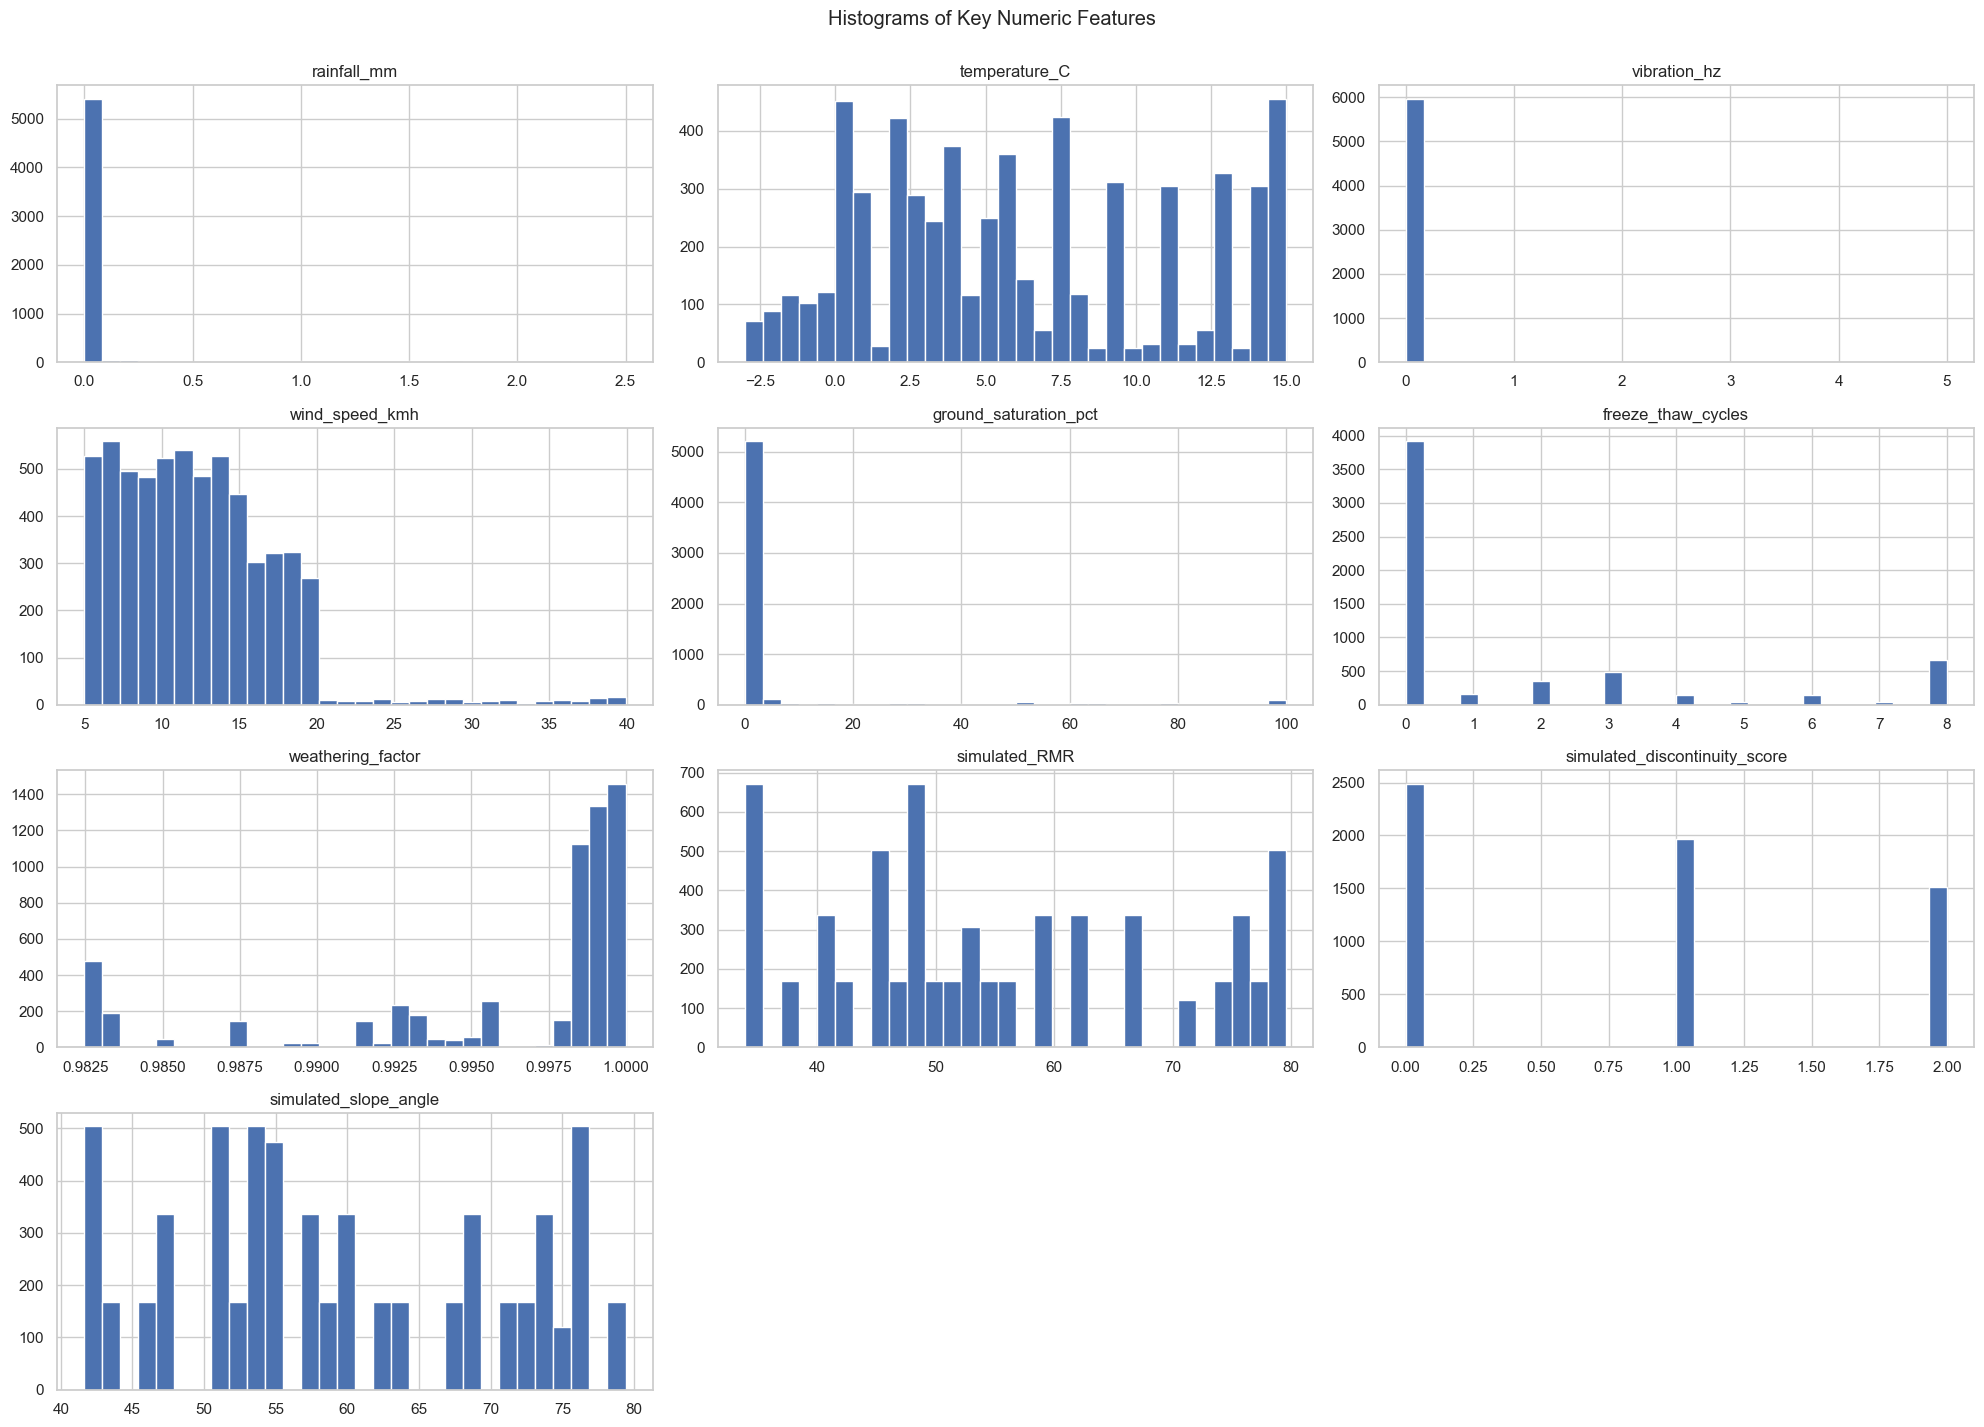

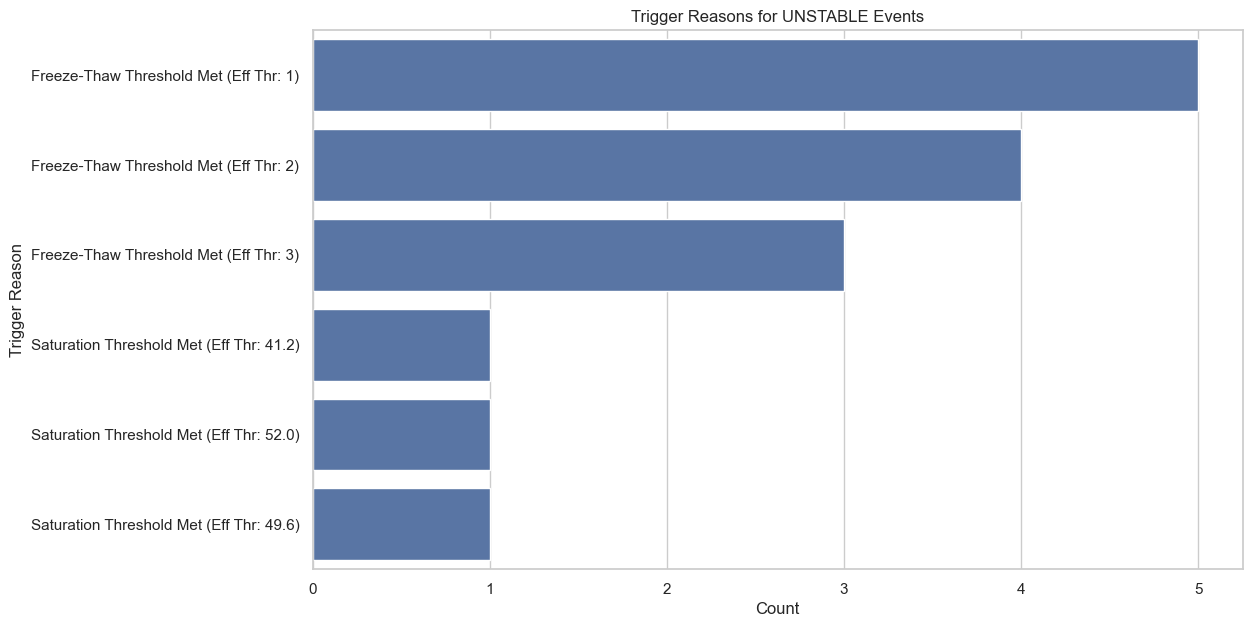

In [4]:
# --- 3. Univariate Feature Analysis ---

# Define the key features to analyze (based on your CSV headers)
features_to_plot = [
    'rainfall_mm', 'temperature_C', 'vibration_hz', 
    'wind_speed_kmh', 'ground_saturation_pct', 'freeze_thaw_cycles',
    'weathering_factor', 'simulated_RMR', 'simulated_discontinuity_score',
    'simulated_slope_angle'
]

# Plot histograms for each feature
df[features_to_plot].hist(bins=30, figsize=(20, 15), layout=(4, 3))
plt.suptitle('Histograms of Key Numeric Features')
plt.tight_layout(rect=[0, 0.03, 1, 0.98])
plt.show()

# Also look at the 'trigger_reason' for rockfalls
plt.figure(figsize=(12, 7))
sns.countplot(y='trigger_reason', data=df[df['LABEL'] == 'UNSTABLE'], order=df[df['LABEL'] == 'UNSTABLE']['trigger_reason'].value_counts().index)
plt.title('Trigger Reasons for UNSTABLE Events')
plt.xlabel('Count')
plt.ylabel('Trigger Reason')
plt.show()

--- Plotting Bivariate Boxplots ---


C:\Users\ASUS\AppData\Local\Temp\ipykernel_22636\2795905877.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='LABEL', y=feature, data=df, palette={'STABLE': 'green', 'UNSTABLE': 'red'})


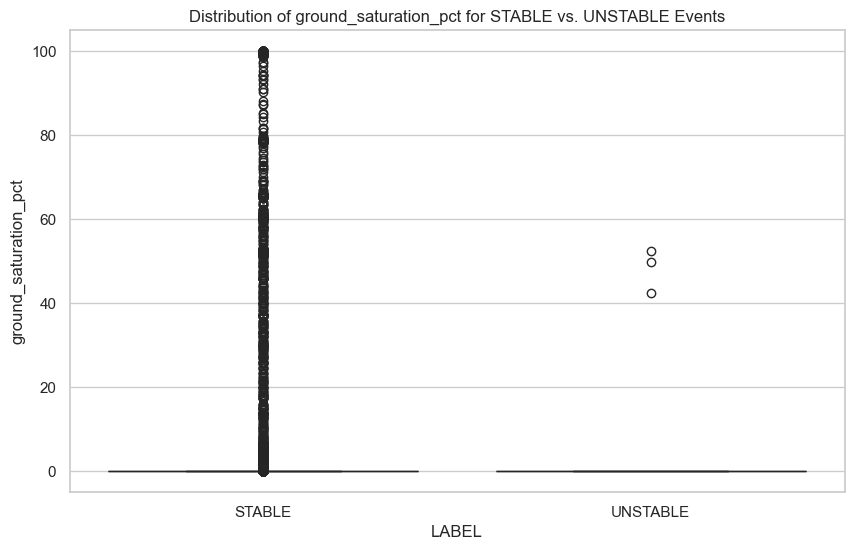

C:\Users\ASUS\AppData\Local\Temp\ipykernel_22636\2795905877.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='LABEL', y=feature, data=df, palette={'STABLE': 'green', 'UNSTABLE': 'red'})


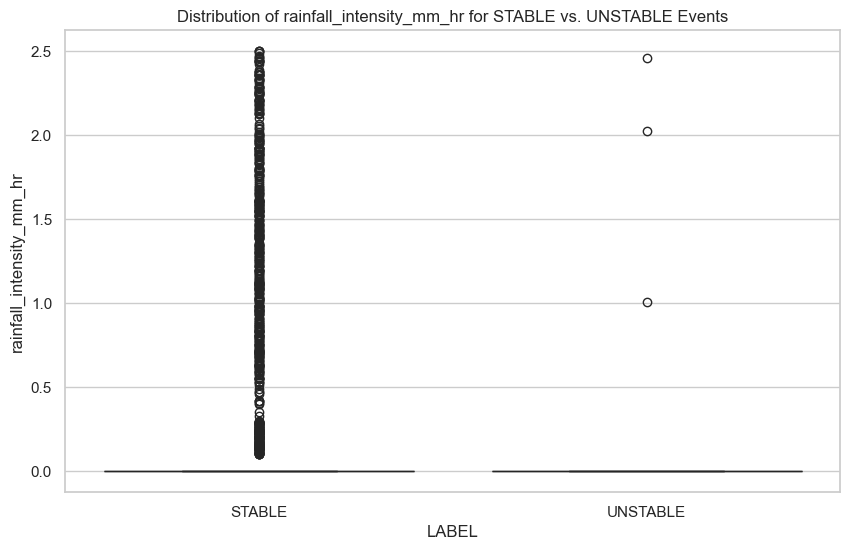

C:\Users\ASUS\AppData\Local\Temp\ipykernel_22636\2795905877.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='LABEL', y=feature, data=df, palette={'STABLE': 'green', 'UNSTABLE': 'red'})


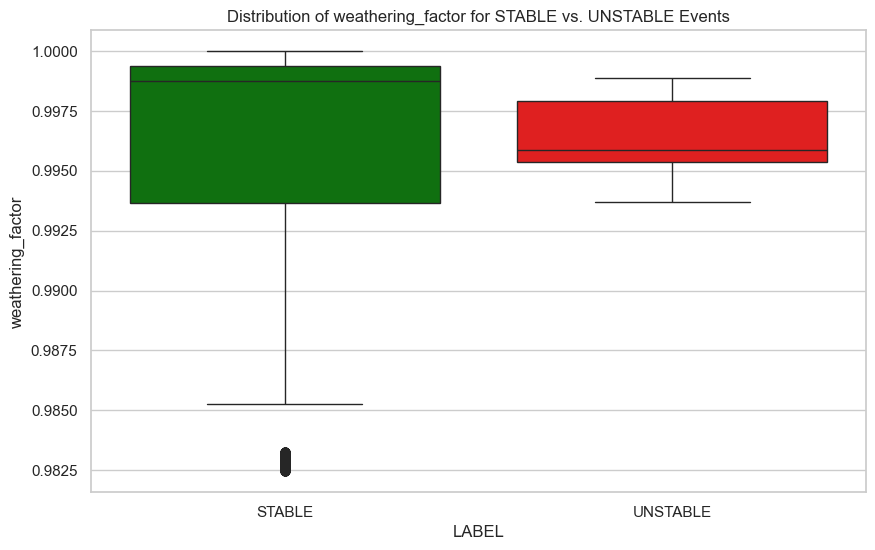

C:\Users\ASUS\AppData\Local\Temp\ipykernel_22636\2795905877.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='LABEL', y=feature, data=df, palette={'STABLE': 'green', 'UNSTABLE': 'red'})


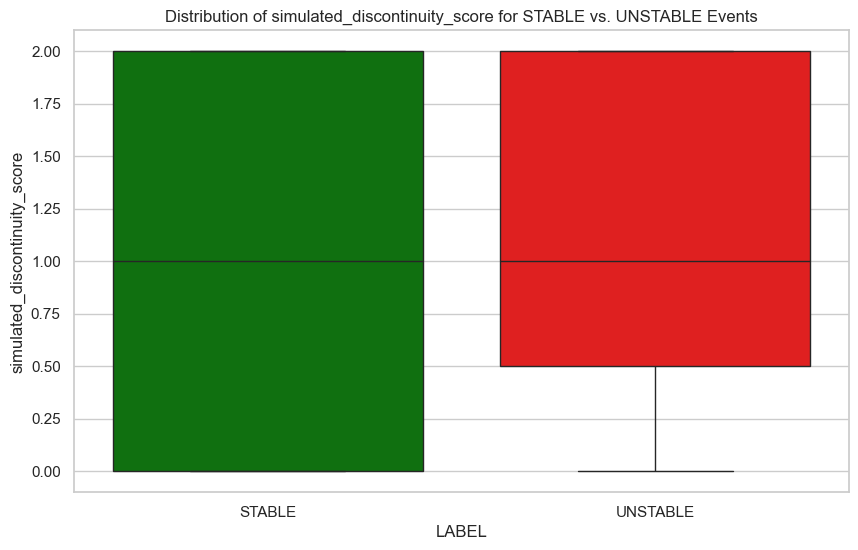

C:\Users\ASUS\AppData\Local\Temp\ipykernel_22636\2795905877.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='LABEL', y=feature, data=df, palette={'STABLE': 'green', 'UNSTABLE': 'red'})


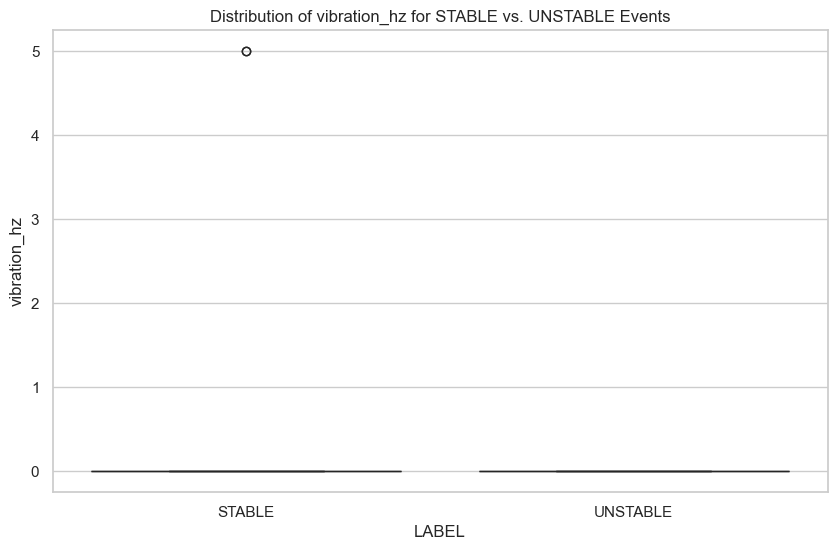

In [5]:
# --- 4. Bivariate Analysis (Features vs. Target) ---

# Let's use boxplots to compare distributions for STABLE vs UNSTABLE
# We'll focus on a few key features mentioned in your problem statement
bivariate_features = [
    'ground_saturation_pct', 'rainfall_intensity_mm_hr', 
    'weathering_factor', 'simulated_discontinuity_score',
    'vibration_hz'
]

print("--- Plotting Bivariate Boxplots ---")
for feature in bivariate_features:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x='LABEL', y=feature, data=df, palette={'STABLE': 'green', 'UNSTABLE': 'red'})
    plt.title(f'Distribution of {feature} for STABLE vs. UNSTABLE Events')
    plt.show()

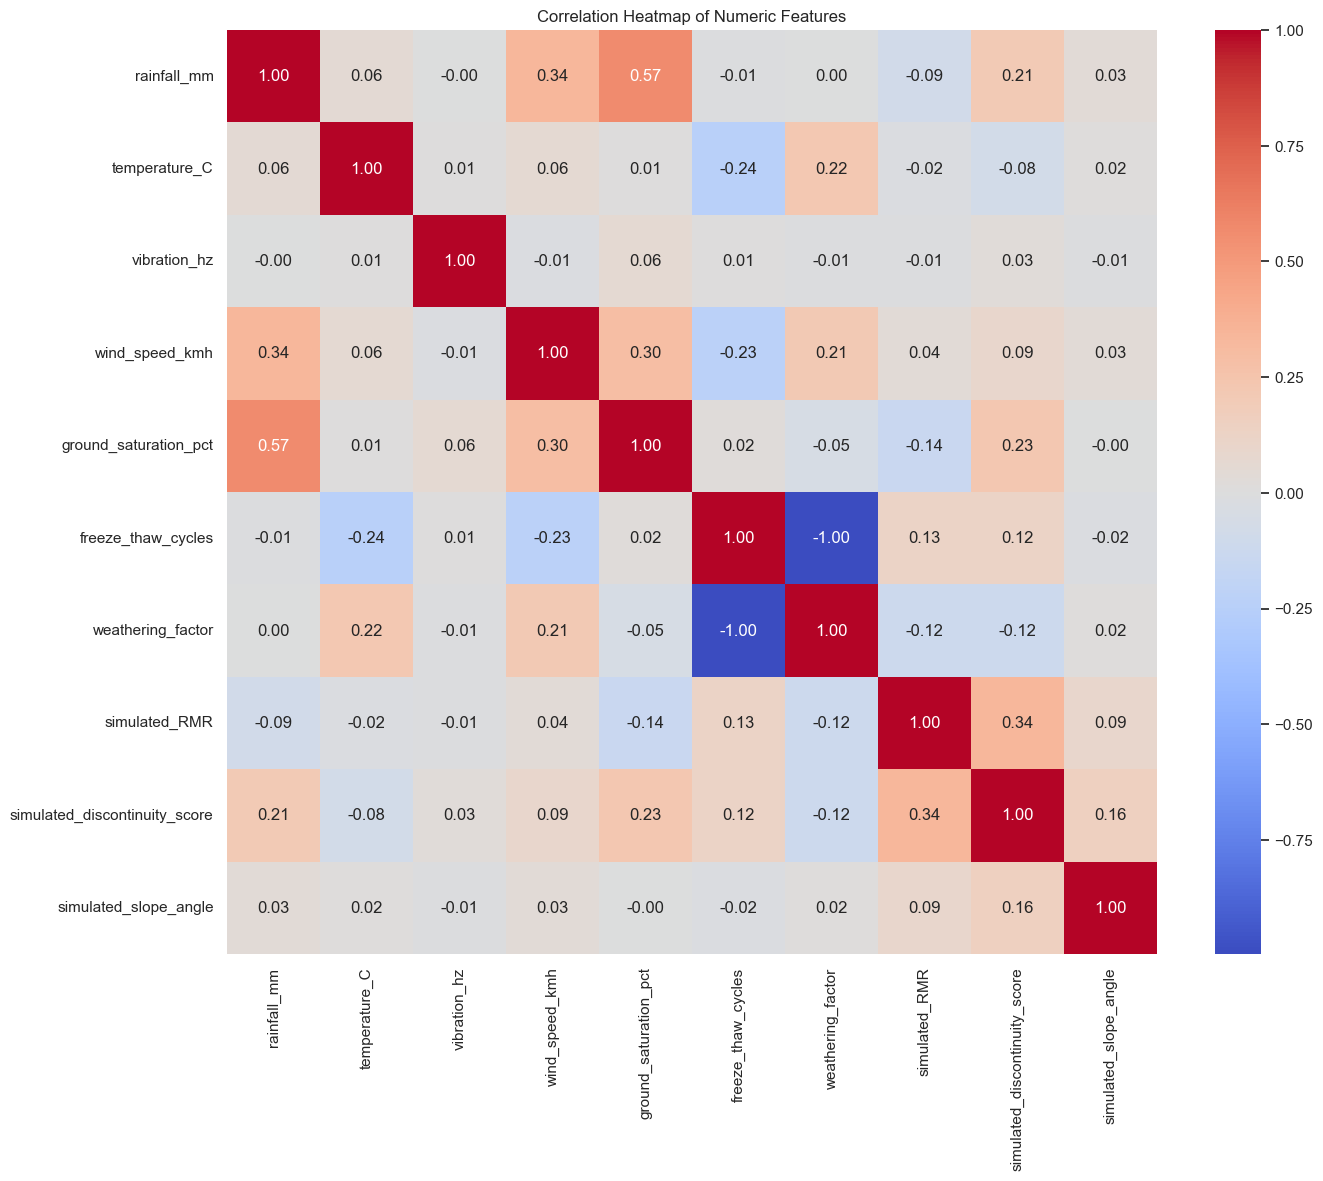

In [6]:
# --- 5. Correlation Analysis ---

# Calculate the correlation matrix
corr_matrix = df[features_to_plot].corr()

# Plot the heatmap
plt.figure(figsize=(15, 12))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap of Numeric Features')
plt.show()


--- Plotting Temporal Data for Scenario: 21 ---


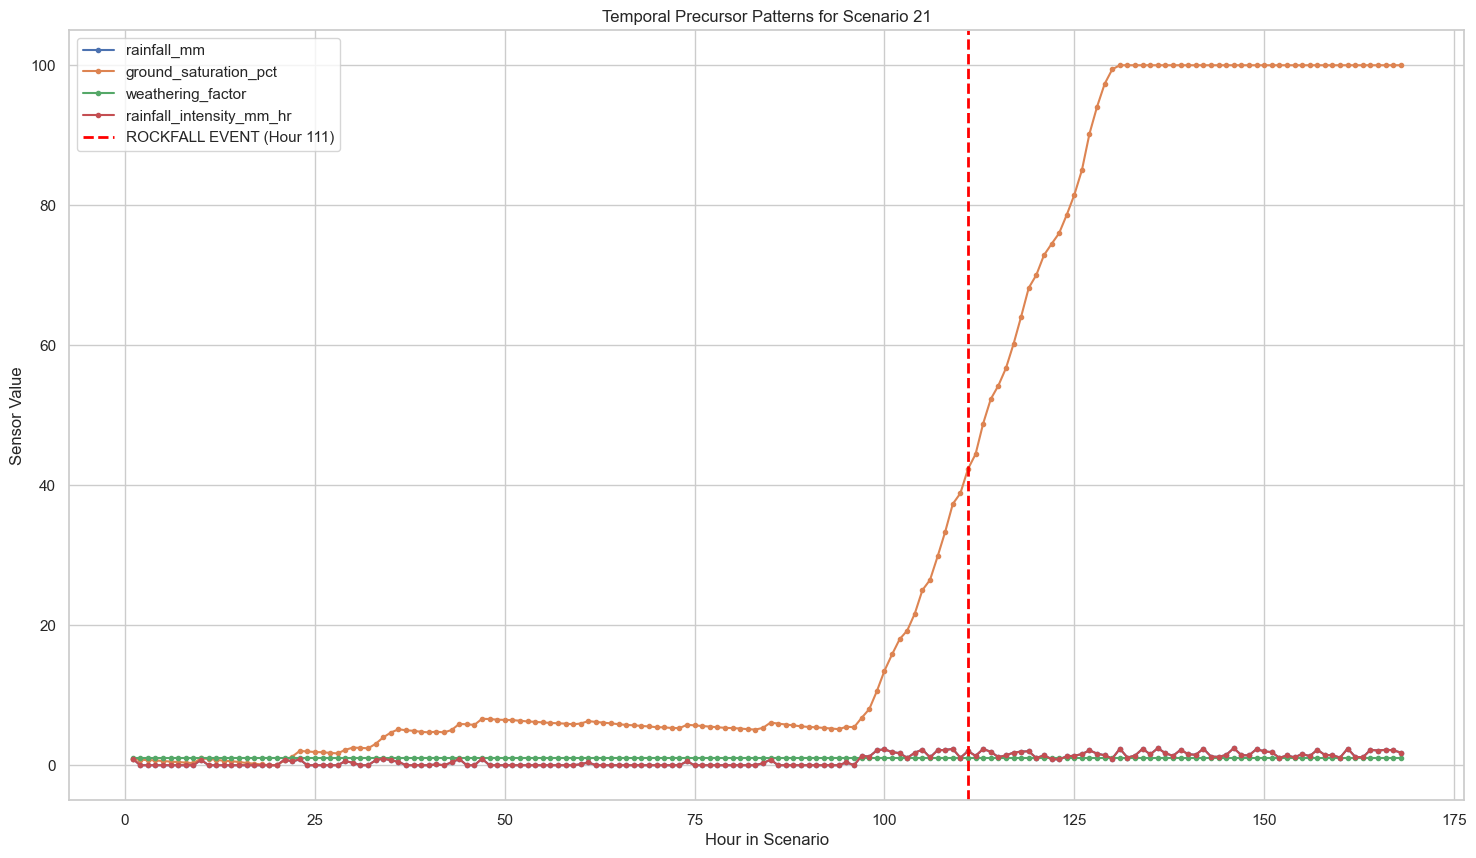

In [7]:
# --- 6. Temporal Analysis (Finding Precursor Patterns) ---

# First, find a scenario_id that contains an 'UNSTABLE' event
unstable_scenarios = df[df['LABEL'] == 'UNSTABLE']['scenario_id'].unique()

if len(unstable_scenarios) > 0:
    # Let's pick the first unstable scenario to analyze
    scenario_to_plot = unstable_scenarios[0]
    print(f"\n--- Plotting Temporal Data for Scenario: {scenario_to_plot} ---")
    
    # Get all data for just this one scenario
    scenario_df = df[df['scenario_id'] == scenario_to_plot].copy()
    
    # Find the hour of the rockfall
    rockfall_hour = scenario_df[scenario_df['LABEL'] == 'UNSTABLE']['hour_in_scenario'].min()
    
    # Define features to plot over time
    temporal_features = [
        'rainfall_mm',
        'ground_saturation_pct',
        'weathering_factor',
        'rainfall_intensity_mm_hr'
    ]
    
    # Create the plot
    fig, ax = plt.subplots(figsize=(18, 10))
    
    # Plot each feature
    for feature in temporal_features:
        ax.plot(scenario_df['hour_in_scenario'], scenario_df[feature], label=feature, marker='.')
    
    # Highlight the rockfall event
    ax.axvline(x=rockfall_hour, color='red', linestyle='--', linewidth=2, label=f'ROCKFALL EVENT (Hour {rockfall_hour})')
    
    ax.set_title(f'Temporal Precursor Patterns for Scenario {scenario_to_plot}')
    ax.set_xlabel('Hour in Scenario')
    ax.set_ylabel('Sensor Value')
    ax.legend()
    ax.grid(True)
    plt.show()

else:
    print("\n--- No unstable scenarios found in the dataset to plot. ---")

Precursor Features (The "Cause"):

ground_saturation_pct: The temporal plot (for scenario 2) clearly shows this feature gradually increasing over time before the rockfall. It is "charged" by rain events and slowly rises. This is a perfect example of a long-term precursor pattern our model must learn.

rainfall_mm: The describe() output shows 75% of its values are 0, but the max is 20. This confirms rain is a sporadic event that drives ground saturation.

temperature_C: The range from -10°C to 20°C confirms that conditions for freeze_thaw_cycles are present.

Effect/Co-incident Feature (The "Result"):

vibration_hz: The describe() output shows 75% of its values are 0. The temporal plot is the "smoking gun": vibration_hz is flat at 0 for the entire scenario and then spikes at the exact hour of the rockfall.

Critical Modeling Decision: This feature is an effect of the rockfall, not a precursor. If we are predicting the LABEL for Hour H using data from before Hour H, this feature will be useless (it will always be 0). If we include data from Hour H (e.g., vibration_hz at Hour H), it becomes a target leak.